# Análise exploratória dos dados



total de classes (nível espécie): 1924

total de classes (nível familia): 264

total de classes (nível ordem): 28

total de imagens: 244.557

Os dados não estão com uma boa distribuição, mas com a arquitetura prevista podemos resolver o problema.

Treinar yolo26 para detectar a ordem do inseto, 1 modelo
Descoberta a ordem: treinar para descobrir a família dentro da ordem, 27 modelos
Descoberta a família: treinar para descobrir a espécie dentro da ordem, 264 modelos (viável?)

Possíveis melhorias: fazer segmentação das imagens para separar o fundo da imagem do inseto (Pegar modelos prontos ou fazer fine tunning usando datasets já segmentados e testar)

In [2]:
%pip install split-folders pandas matplotlib seaborn scikit-learn huggingface_hub supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 855.2/855.2 kB 17.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 471.2/471.2 kB 30.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 40.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 48.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.1/85.1 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 7.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [18]:
# imports
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import os
from PIL import Image
import splitfolders
from ultralytics import YOLOE
import supervision as sv
import cv2
from huggingface_hub import hf_hub_download
import numpy as np

In [2]:
def get_df(path):
    
    dataset_path = Path(path)

    data = []

    for pasta_categoria in dataset_path.iterdir():
        if pasta_categoria.is_dir():
            categoria_nome = pasta_categoria.name
            
            total_imagens = sum(1 for arquivo in pasta_categoria.iterdir())
            
            data.append({
                "categoria": categoria_nome,
                "quantidade_imagens": total_imagens
            })
    df = pd.DataFrame(data)
    return df


In [3]:
# métricas a nivel de espécie
df_species = get_df('/home/bradachi/Downloads/datasets/final/especies')
df_species

,categoria,quantidade_imagens
0,Zelus luridus,53
1,Haematopinus asini,43
2,Bembidion decorum,320
3,Agrotis orthogonia,62
4,Leptogaster,56
...,...,...
1919,Trypodendron lineatum,92
1920,Notiophilus palustris,284
1921,Xanthogaleruca luteola,77
1922,Campsomeris,52


In [4]:
df_species['quantidade_imagens'].describe()

count    1924.000000
mean      127.108628
std       170.869226
min         2.000000
25%        54.000000
50%        68.000000
75%       105.000000
max      1374.000000
Name: quantidade_imagens, dtype: float64

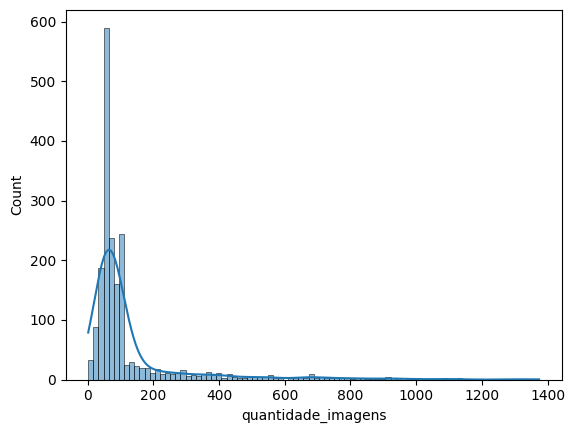

In [14]:
sns.histplot(data=df_species, x='quantidade_imagens', kde=True)
plt.show()


In [5]:
# métricas a nivel de familia
df_familia = get_df('/home/bradachi/Downloads/datasets/familia')
df_familia

,categoria,quantidade_imagens
0,Calliphoridae,342
1,Tungidae,19
2,Lygaeidae,400
3,Gracillariidae,765
4,Scutigerellidae,46
...,...,...
259,Cleridae,1053
260,Tettigoniidae,599
261,Papilionidae,855
262,Cossidae,240


In [6]:
df_familia['quantidade_imagens'].describe()

count      264.000000
mean       925.113636
std       4382.472970
min          3.000000
25%         61.750000
50%        157.000000
75%        571.250000
max      67879.000000
Name: quantidade_imagens, dtype: float64

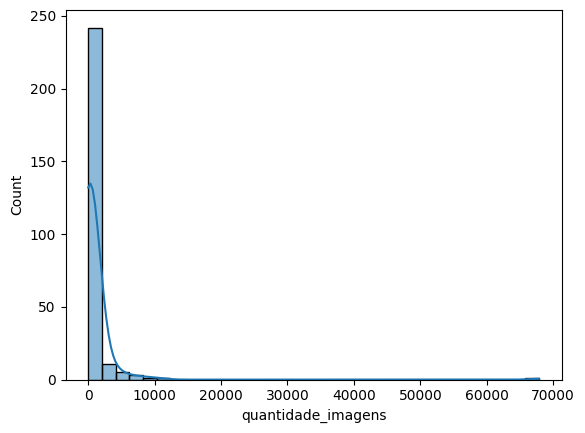

In [11]:
sns.histplot(data=df_familia, x='quantidade_imagens', kde=True)
plt.show()

In [7]:
# métricas a nivel de ordem
df_ordem = get_df('/home/bradachi/Downloads/datasets/ordem')
df_ordem

,categoria,quantidade_imagens
0,Thysanoptera,3187
1,Diptera,17375
2,Mantodea,222
3,Embioptera,32
4,Coleoptera,103588
5,Blattodea,1736
6,Phasmida,158
7,Hymenoptera,23349
8,Mesostigmata,171
9,Neuroptera,352


In [8]:
df_ordem['quantidade_imagens'].describe()

count        28.000000
mean       8722.500000
std       21699.790585
min          28.000000
25%         209.250000
50%         651.000000
75%        2446.000000
max      103588.000000
Name: quantidade_imagens, dtype: float64

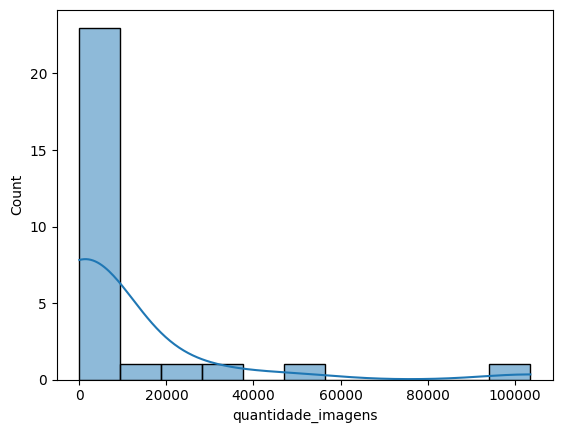

In [12]:
sns.histplot(data=df_ordem, x='quantidade_imagens', kde=True)
plt.show()

In [4]:
dados = list()
def metrica_resolucao(pasta_imagens):
    # Extensões válidas de imagem

    print(pasta_imagens)
    extensoes_validas = (".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tiff")

    larguras = []
    alturas = []

    # Percorre todos os arquivos da pasta
    for arquivo in os.listdir(pasta_imagens):
        if arquivo.lower().endswith(extensoes_validas):
            caminho_completo = os.path.join(pasta_imagens, arquivo)
            try:
                with Image.open(caminho_completo) as img:
                    largura, altura = img.size
                    larguras.append(largura)
                    alturas.append(altura)
            except Exception as e:
                print(f"Erro ao abrir o arquivo {arquivo}: {e}")

    # Calcula a média se houver imagens
    if len(larguras) > 0:
        media_largura = sum(larguras) / len(larguras)
        media_altura = sum(alturas) / len(alturas)
        
        print(f"Total de imagens analisadas: {len(larguras)}")
        print(f"Resolução média: {media_largura:.2f} x {media_altura:.2f} pixels")
        dados.append((media_largura, media_altura))
        print(f"Resolução média arredondada: {round(media_largura)} x {round(media_altura)} pixels")
    else:
        print("Nenhuma imagem válida encontrada na pasta.")

def dataset_resolucao(pasta_origem):
    for arquivo in os.listdir(pasta_origem):
        metrica_resolucao(f'{pasta_origem}/{arquivo}')


In [5]:
dataset_resolucao("/home/bradachi/Downloads/datasets/ordem")

/home/bradachi/Downloads/datasets/ordem/Thysanoptera
Total de imagens analisadas: 3186
Resolução média: 562.84 x 444.27 pixels
Resolução média arredondada: 563 x 444 pixels
/home/bradachi/Downloads/datasets/ordem/Diptera
Total de imagens analisadas: 17367
Resolução média: 502.74 x 412.07 pixels
Resolução média arredondada: 503 x 412 pixels
/home/bradachi/Downloads/datasets/ordem/Mantodea
Total de imagens analisadas: 222
Resolução média: 523.01 x 414.50 pixels
Resolução média arredondada: 523 x 414 pixels
/home/bradachi/Downloads/datasets/ordem/Embioptera
Total de imagens analisadas: 32
Resolução média: 523.44 x 375.69 pixels
Resolução média arredondada: 523 x 376 pixels
/home/bradachi/Downloads/datasets/ordem/Coleoptera
Total de imagens analisadas: 103570
Resolução média: 413.22 x 516.00 pixels
Resolução média arredondada: 413 x 516 pixels
/home/bradachi/Downloads/datasets/ordem/Blattodea
Total de imagens analisadas: 1730
Resolução média: 607.98 x 452.82 pixels
Resolução média arredond

/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (122922240 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Total de imagens analisadas: 23347
Resolução média: 476.93 x 407.34 pixels
Resolução média arredondada: 477 x 407 pixels
/home/bradachi/Downloads/datasets/ordem/Mesostigmata
Total de imagens analisadas: 171
Resolução média: 383.42 x 317.98 pixels
Resolução média arredondada: 383 x 318 pixels
/home/bradachi/Downloads/datasets/ordem/Neuroptera
Total de imagens analisadas: 352
Resolução média: 640.80 x 469.15 pixels
Resolução média arredondada: 641 x 469 pixels
/home/bradachi/Downloads/datasets/ordem/Symphypleona
Total de imagens analisadas: 28
Resolução média: 391.43 x 281.43 pixels
Resolução média arredondada: 391 x 281 pixels
/home/bradachi/Downloads/datasets/ordem/Psocodea
Total de imagens analisadas: 1072
Resolução média: 429.76 x 345.90 pixels
Resolução média arredondada: 430 x 346 pixels
/home/bradachi/Downloads/datasets/ordem/Trombidiformes
Total de imagens analisadas: 2198
Resolução média: 513.04 x 397.21 pixels
Resolução média arredondada: 513 x 397 pixels
/home/bradachi/Downloa

In [ ]:
# Estatística das médias do tamanho de imagem por classe
df = pd.DataFrame(dados)
df.describe()


,0,1
count,27.000000,27.000000
mean,488.151415,394.580996
std,107.175996,77.038750
min,152.502116,147.868829
25%,428.749468,358.595282
50%,502.741176,403.338983
75%,551.685909,441.324967
max,712.142857,530.561224


Acredito que redimencionar as imagens para 512x512 vai ser uma boa opção

In [ ]:
# dataset real
input_folder = "/home/bradas/Downloads/ordem"

# Pasta de saída que será criada com os subconjuntos
output_folder = "/home/bradas/Downloads/ordem_yolo"

# Dividindo na proporção: 80% treino e 20% teste
splitfolders.ratio(
    input_folder,
    output=output_folder,
    seed=1337,
    ratio=(0.8, 0.2),  # (treino, teste)
)

In [19]:
# dataset real
input_folder = "/home/bradas/Downloads/insetos/familia"

# Pasta de saída que será criada com os subconjuntos
output_folder = "/home/bradas/Downloads/insetos/familia_yolo"

# Dividindo na proporção: 80% treino e 20% teste
splitfolders.ratio(
    input_folder,
    output=output_folder,
    seed=1337,
    ratio=(0.8, 0.2),  # (treino, teste)
)

Copying files: 244230 files [01:34, 2574.63 files/s]


In [ ]:
# toy dataset
splitfolders.ratio(
    input_folder,
    output="/home/bradas/Downloads/ordem_yolo_toy",
    seed=1337,
    ratio=(0.94, 0.05, 0.01),  # (descarte, treino, teste)
)

In [20]:
# toy dataset
splitfolders.ratio(
    input_folder,
    output="/home/bradas/Downloads/insetos/familia_yolo_toy",
    seed=1337,
    ratio=(0.94, 0.05, 0.01),  # (descarte, treino, teste)
)

Copying files: 244230 files [02:02, 1990.02 files/s]


In [5]:
# Gerando imagens recortadas pelo SAM3

model_path = hf_hub_download(repo_id="openvision/yoloe26-s-seg", filename="model.pt")


model = YOLOE(model_path)

CLASSES_CUSTOMIZADAS = ["bug","bugs", "insect", "insects", "inseto"]

model.set_classes(CLASSES_CUSTOMIZADAS, model.get_text_pe(CLASSES_CUSTOMIZADAS))

/home/bradas/Documentos/github/ml-engineering/.venv/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [13]:
def resultado_YOLOzs(caminho_imagem):
    imagem = Image.open(caminho_imagem)
    results = model.predict(imagem, conf=0.25)

    detections = sv.Detections.from_ultralytics(results[0])
    imagem_bgr = cv2.imread(caminho_imagem)
    if len(detections) > 0 and detections.mask is not None:

        mascara_combinada = np.any(detections.mask, axis=0)

        mascara_uint8 = (mascara_combinada * 255).astype(np.uint8)

        imagem_sem_fundo = cv2.bitwise_and(imagem_bgr, imagem_bgr, mask=mascara_uint8)

        x_min = int(np.min(detections.xyxy[:, 0]))
        y_min = int(np.min(detections.xyxy[:, 1]))
        x_max = int(np.max(detections.xyxy[:, 2]))
        y_max = int(np.max(detections.xyxy[:, 3]))

        imagem_final = imagem_sem_fundo[y_min:y_max, x_min:x_max]

    else:
        print("Nenhuma máscara detectada.")
        imagem_final = imagem_bgr

    # imagem_rgb = cv2.cvtColor(imagem_final, cv2.COLOR_BGR2RGB)

    # plt.figure(figsize=(10, 10))
    # plt.imshow(imagem_rgb)
    # plt.axis('off')            
    # plt.show()

    
    return imagem_final


In [14]:
resultado_YOLOzs("/home/bradas/Downloads/ordem_yolo_toy/val/Araneae/7ca46211-5680-4580-b0ed-e399ec98b628.jpg")



0: 416x640 1 insect, 6.9ms
Speed: 0.8ms preprocess, 6.9ms inference, 0.9ms postprocess per image at shape (1, 3, 416, 640)


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(210, 286, 3), dtype=uint8)

In [15]:
def dataset_segmentado(pasta_origem, pasta_destino):
  os.makedirs(pasta_destino, exist_ok=True)

  for raiz, _, arquivos in os.walk(pasta_origem):
    caminho_relativo = os.path.relpath(raiz, pasta_origem)

    subpasta_destino = os.path.join(pasta_destino, caminho_relativo)
    os.makedirs(subpasta_destino, exist_ok=True)

    for item, arquivo in enumerate(arquivos, start=1):
      print(f'[ {item} / {len(arquivos)} ]')

      caminho_arquivo_origem = os.path.join(raiz, arquivo)
      caminho_arquivo_destino = os.path.join(subpasta_destino, arquivo)

      img = resultado_YOLOzs(caminho_arquivo_origem)

      cv2.imwrite(caminho_arquivo_destino, img)

In [16]:
dataset_segmentado("/home/bradas/Downloads/ordem_yolo_toy/train", "/home/bradas/Downloads/ordem_yolo_toy_seg/train")

[ 1 / 159 ]

0: 448x640 1 inseto, 13.3ms
Speed: 0.8ms preprocess, 13.3ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)
[ 2 / 159 ]

0: 480x640 1 inseto, 14.4ms
Speed: 0.9ms preprocess, 14.4ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)
[ 3 / 159 ]

0: 480x640 1 insect, 7.4ms
Speed: 1.0ms preprocess, 7.4ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)
[ 4 / 159 ]

0: 512x640 1 insect, 13.1ms
Speed: 0.8ms preprocess, 13.1ms inference, 0.9ms postprocess per image at shape (1, 3, 512, 640)
[ 5 / 159 ]

0: 480x640 1 insect, 7.6ms
Speed: 0.8ms preprocess, 7.6ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 640)
[ 6 / 159 ]

0: 480x640 1 bugs, 7.5ms
Speed: 1.0ms preprocess, 7.5ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)
[ 7 / 159 ]

0: 640x640 (no detections), 13.6ms
Speed: 1.0ms preprocess, 13.6ms inference, 0.2ms postprocess per image at shape (1, 3, 640, 640)
Nenhuma máscara detectada.
[ 8 / 15

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


Nenhuma máscara detectada.
[ 7 / 24 ]

0: 480x640 1 inseto, 6.8ms
Speed: 0.9ms preprocess, 6.8ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 640)
[ 8 / 24 ]

0: 448x640 1 insect, 9.9ms
Speed: 0.9ms preprocess, 9.9ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)
[ 9 / 24 ]

0: 448x640 1 bug, 6.3ms
Speed: 0.8ms preprocess, 6.3ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)
[ 10 / 24 ]

0: 544x640 1 insect, 7.8ms
Speed: 1.0ms preprocess, 7.8ms inference, 1.0ms postprocess per image at shape (1, 3, 544, 640)
[ 11 / 24 ]

0: 448x640 (no detections), 7.1ms
Speed: 1.4ms preprocess, 7.1ms inference, 0.3ms postprocess per image at shape (1, 3, 448, 640)
Nenhuma máscara detectada.
[ 12 / 24 ]

0: 640x448 (no detections), 6.8ms
Speed: 0.8ms preprocess, 6.8ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 448)
Nenhuma máscara detectada.
[ 13 / 24 ]

0: 512x640 (no detections), 6.7ms
Speed: 0.8ms preprocess, 6.7ms inference, 0.3ms 

libpng warning: iCCP: profile 'ICC Profile': 0h: PCS illuminant is not D50


0: 640x640 (no detections), 8.2ms
Speed: 0.9ms preprocess, 8.2ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Nenhuma máscara detectada.
[ 48 / 109 ]

0: 512x640 1 inseto, 6.8ms
Speed: 0.7ms preprocess, 6.8ms inference, 1.0ms postprocess per image at shape (1, 3, 512, 640)
[ 49 / 109 ]

0: 480x640 (no detections), 7.1ms
Speed: 0.9ms preprocess, 7.1ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)
Nenhuma máscara detectada.
[ 50 / 109 ]

0: 352x640 (no detections), 6.4ms
Speed: 0.6ms preprocess, 6.4ms inference, 0.3ms postprocess per image at shape (1, 3, 352, 640)
Nenhuma máscara detectada.
[ 51 / 109 ]

0: 480x640 (no detections), 7.0ms
Speed: 0.9ms preprocess, 7.0ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)
Nenhuma máscara detectada.
[ 52 / 109 ]

0: 544x640 (no detections), 7.8ms
Speed: 0.8ms preprocess, 7.8ms inference, 0.3ms postprocess per image at shape (1, 3, 544, 640)
Nenhuma máscara detectada.
[ 53 / 109 ]

0: 416x6

In [17]:
dataset_segmentado("/home/bradas/Downloads/ordem_yolo_toy/val", "/home/bradas/Downloads/ordem_yolo_toy_seg/val")

[ 1 / 33 ]

0: 384x640 1 inseto, 7.0ms
Speed: 21.1ms preprocess, 7.0ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 640)
[ 2 / 33 ]

0: 640x608 (no detections), 10.0ms
Speed: 0.8ms preprocess, 10.0ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 608)
Nenhuma máscara detectada.
[ 3 / 33 ]

0: 640x480 (no detections), 8.9ms
Speed: 1.0ms preprocess, 8.9ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 480)
Nenhuma máscara detectada.
[ 4 / 33 ]

0: 640x640 (no detections), 10.2ms
Speed: 0.9ms preprocess, 10.2ms inference, 0.4ms postprocess per image at shape (1, 3, 640, 640)
Nenhuma máscara detectada.
[ 5 / 33 ]

0: 416x640 (no detections), 7.4ms
Speed: 1.4ms preprocess, 7.4ms inference, 0.4ms postprocess per image at shape (1, 3, 416, 640)
Nenhuma máscara detectada.
[ 6 / 33 ]

0: 512x640 1 insect, 8.2ms
Speed: 0.9ms preprocess, 8.2ms inference, 1.0ms postprocess per image at shape (1, 3, 512, 640)
[ 7 / 33 ]

0: 480x640 (no detections), 8.5ms
Spe